# 02 · Baselines and validation

[Guide](../README.md) | [Previous](01_Exploratory_Data_Analysis.ipynb) | [Next](03_Missing_Values_and_Scaling.ipynb)

## 1. What problem are we solving?

Does a model learn more than a simple guess?

## 2. Why does it matter?

A high-looking score means little if a trivial rule achieves the same result.

## 3. Key concepts

| Term | Simple meaning |
|---|---|
| Baseline | An easy reference to beat before claiming the model learned something useful. |
| Holdout | Split once: fit on one part and check predictions on the other. |
| Cross-validation | Rotate several held-out groups inside training, then average their scores. |
| Stratified | Keep roughly the same goal/miss proportions in each split. |
| Precision / recall / F1 | Correctness of predicted goals / fraction of real goals found / a balance of both. |
| Accuracy | The fraction of all kicks predicted correctly. |
| ROC-AUC | How well scores rank goals above misses across cutoffs: 0.5 is random ranking; 1 is perfect. |
| F1 spread | Variation in F1 across the three folds; not a formal confidence interval. |

## 4. Intuitive example

For an illustrative 100 kicks with 55 misses and 45 goals: always predicting miss gets 55% accuracy but goal F1 = 0. Always predicting goal gets only 45% accuracy but F1 ≈ 0.621. A useful model must beat sensible baselines on the metric we care about.

## 5. Methods to compare

| Method | Prediction rule | Trade-off |
|---|---|---|
| Common-class baseline | Always predict the most frequent answer | Can have acceptable accuracy but zero goal F1 |
| Stratified random baseline | Guess with training class proportions | No learned relationship; depends on random seed |
| Always-goal baseline | Predict a goal for every kick | Finds all goals but also predicts many misses as goals |
| Logistic regression | Learn weights from the inputs | Clear baseline; simple relationships can miss interactions |

## 6. What we retained from previous notebooks

**Prior knowledge:** From 01: 20,000 labeled rows and 6,000 unlabeled test rows; no exact duplicates observed; four IDs are identifiers, not direct predictive inputs.

**Carry forward:** Class ratio ≈55% miss /45% goal; inspect missing inputs and unusual observations later.

## 7. Setup

**Reusable setup — run this cell, then skip to the lesson.** You do not need to study all these lines now: they load the data and rebuild earlier steps so this notebook works on its own. Revisit the earlier lessons for explanations.

Change `DATA_DIR` for your runtime. The cell starts collapsed where the editor supports it; GitHub may show it expanded. `X` contains inputs; `y` contains known answers. Learned preparation stays inside training folds.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.precision", 3)

# Change this one folder on Kaggle or Colab (see the guide).
DATA_DIR = "../data"
train = pd.read_csv(f"{DATA_DIR}/train.csv")
test = pd.read_csv(f"{DATA_DIR}/test.csv")
print("Train:", train.shape, "Test:", test.shape)

# Split train.csv: 80% for training, 20% for a separate validation check.
training_data, validation_data = train_test_split(
    train, test_size=0.20, stratify=train["is_scored"], random_state=2026
)
training_data = training_data.reset_index(drop=True)

# IDs identify rows; they do not describe how a penalty was taken.
id_columns = ["id", "kicker_id", "keeper_id", "match_id"]
X = training_data.drop(columns=id_columns + ["is_scored"])
y = training_data["is_scored"]

numeric_columns = X.select_dtypes(include="number").columns
category_columns = X.select_dtypes(exclude="number").columns

numbers = make_pipeline(SimpleImputer(strategy="median"), StandardScaler())
categories = make_pipeline(
    SimpleImputer(strategy="most_frequent"),
    OneHotEncoder(handle_unknown="ignore", sparse_output=False),
)
preprocess = ColumnTransformer([
    ("numbers", numbers, numeric_columns),
    ("categories", categories, category_columns),
])

# Each fold trains on two parts and predicts the third, unseen part.
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

def compare(models, X, y):
    rows = []
    for name, model in models.items():
        scores = cross_validate(model, X, y, cv=cv, scoring=["f1", "accuracy", "roc_auc"])
        rows.append([name, scores["test_f1"].mean(), scores["test_f1"].std(),
                     scores["test_accuracy"].mean(), scores["test_roc_auc"].mean()])
    columns = ["method", "F1", "F1 spread", "accuracy", "ROC-AUC"]
    return pd.DataFrame(rows, columns=columns).sort_values("F1", ascending=False)

Train: (20000, 20) Test: (6000, 19)


## 8. Experiments

Run the topic-specific steps below. Saved experimental outputs are retained from the earlier runs; regrouping setup does not create a new evaluation.

In [7]:
from sklearn.dummy import DummyClassifier
models = {
    "Always predict the common class": make_pipeline(preprocess, DummyClassifier(strategy="most_frequent")),
    "Random guesses with the same class proportions": make_pipeline(preprocess, DummyClassifier(strategy="stratified", random_state=42)),
    "Always predict a goal": make_pipeline(preprocess, DummyClassifier(strategy="constant", constant=1)),
    "Logistic regression": make_pipeline(preprocess, LogisticRegression(max_iter=1000)),
}

,method,F1,F1 spread,accuracy,ROC-AUC
3,Logistic regression,0.851,0.003,0.866,0.941
2,Always predict a goal,0.621,0.000,0.450,0.500
1,Random guesses with the same class proportions,0.446,0.008,0.502,0.497
0,Always predict the common class,0.000,0.000,0.550,0.500


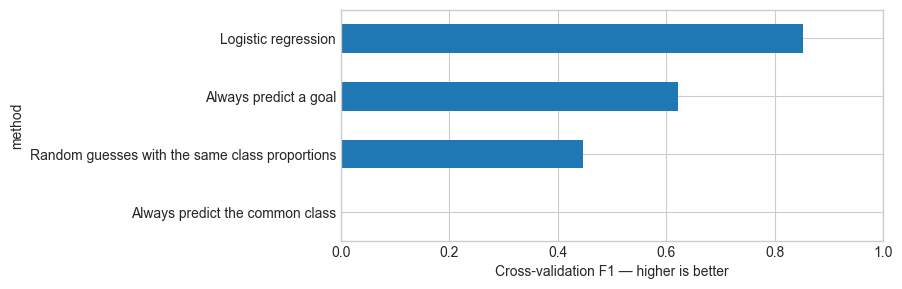

In [8]:
results = compare(models, X, y)
display(results.round(3))
results.set_index("method")["F1"].sort_values().plot.barh(figsize=(7, 3))
plt.xlabel("Cross-validation F1 — higher is better")
plt.xlim(0, 1)
plt.show()

### Why this comparison?

A baseline is the minimum to beat. The same folds and metric make the comparison fair. Split before preprocessing so validation answers cannot influence training.

### Validation alternatives

| Method | When useful | Limitation |
|---|---|---|
| Stratified holdout | One clear training/validation split | Depends on that split |
| Stratified K-fold | Compare methods across several hidden groups | More fitting |
| Group split | Keep the same player/match out of both sides when predicting unseen groups | Fewer independent groups |
| Time split | Train on earlier events, predict later ones | Needs reliable event dates |

We use a stratified holdout for the final check and K-fold within training for method comparisons.
IDs are not dates. This project measures new rows from this dataset, not guaranteed generalization to entirely unseen players.
An always-goal baseline can have nonzero F1 without learning anything; accuracy and the confusion matrix expose that limitation.

### One worked example
A **threshold** turns a probability into a class: at 0.5, predict a goal if the probability is at least 50%.

,actual,goal probability,prediction
8006,0,0.590,1
8356,0,0.150,0
13894,1,0.937,1
14910,1,0.976,1
3100,0,0.084,0


F1: 0.851
Accuracy: 0.868


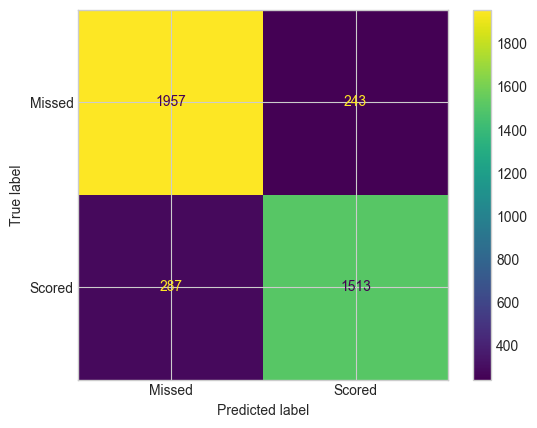

In [9]:
from sklearn.metrics import ConfusionMatrixDisplay, f1_score, accuracy_score
X_fit, X_valid, y_fit, y_valid = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
model = make_pipeline(preprocess, LogisticRegression(max_iter=1000))
model.fit(X_fit, y_fit)
probabilities = model.predict_proba(X_valid)[:, 1]
predictions = (probabilities >= 0.5).astype(int)
example = pd.DataFrame({"actual": y_valid, "goal probability": probabilities, "prediction": predictions})
display(example.head())
print("F1:", round(f1_score(y_valid, predictions), 3))
print("Accuracy:", round(accuracy_score(y_valid, predictions), 3))
ConfusionMatrixDisplay.from_predictions(y_valid, predictions, display_labels=["Missed", "Scored"])
plt.show()

These scores compare predictions with known **validation** answers—not hidden competition-test answers.

### Example: where do the metric numbers come from?
**Precision** = correct predicted goals / all predicted goals.
**Recall** = found goals / all actual goals. **F1** = 2 × precision × recall / (precision + recall).
Accuracy = all correct / all kicks. `tn`, `fp`, `fn`, `tp` count the four confusion-matrix boxes.

In [10]:
from sklearn.metrics import confusion_matrix
tn, fp, fn, tp = confusion_matrix(y_valid, predictions).ravel()
precision = tp / (tp + fp)
recall = tp / (tp + fn)
worked_metrics = pd.Series({
    "precision": precision,
    "recall": recall,
    "F1 from counts": 2 * precision * recall / (precision + recall),
    "F1 from sklearn": f1_score(y_valid, predictions),
    "accuracy from counts": (tp + tn) / len(y_valid),
})
display(worked_metrics.round(4))

precision               0.862
recall                  0.841
F1 from counts          0.851
F1 from sklearn         0.851
accuracy from counts    0.868
dtype: float64

## 9. Results and decision

| Question | Answer |
|---|---|
| What did we compare? | Common-class, always-goal, stratified-random, and logistic-regression predictions, on the same cross-validation folds. |
| Which performed best? | Logistic regression — mean CV F1 0.8510 (rounded saved result). |
| Why did we choose it? | The learned linear baseline beats the simple guessing rules; keep a modest benchmark before adding complexity. |
| What are its limitations? | Simple baselines can miss nonlinear patterns. Small fold differences may be noise; player/match independence needs a group split if that is the intended use. |
| What continues to the next notebook? | Use logistic regression as the learned baseline; keep the same 80/20 split and three-fold training comparisons. |

## 10. Key takeaways and next step

- A trivial rule can look good on accuracy; compare it on the project metric too.
- Use training cross-validation for choices and hold validation aside for the fixed recipe.

Next: [03 Missing Values and Scaling](03_Missing_Values_and_Scaling.ipynb).